# 로컬 LLM 검증
저장된 실제 결과. 새 모델 호출 없음.

## 1. 기록 불러오기

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 이 노트북 안에 보관한 실제 기록을 읽습니다.
candidates = [Path('local_model_check.ipynb'), Path('notebooks/local_model_check.ipynb')]
notebook_path = next(path for path in candidates if path.exists())
notebook = json.loads(notebook_path.read_text(encoding='utf-8'))
data = notebook['metadata']['local_validation_snapshot']
names = {'planner': '기획·슈퍼바이저', 'analyst': '분석', 'organizer': '구성', 'writer': '작성', 'reviewer': '검토', 'slides': '슬라이드'}
print('CPU:', data['hardware']['cpu'])
print('메모리: 약 16GB / 실행: CPU')


CPU: Intel Core i7-4770K @ 3.50GHz
메모리: 약 16GB / 실행: CPU


## 2. 현재 모델 배정

In [2]:
models = pd.DataFrame([{'역할': names[role], '모델': setting['model']}
                       for role, setting in data['configuration'].items()])
display(models)

,역할,모델
0,분석,ollama:qwen3:1.7b
1,구성,ollama:qwen3:1.7b
2,기획·슈퍼바이저,ollama:qwen3:4b
3,검토,ollama:qwen3:4b
4,슬라이드,ollama:qwen3:1.7b
5,작성,ollama:qwen3:1.7b


## 3. 5단계 실행 기록
이 실행의 검토자는 **1.7B**. 현재 검토자는 **4B**로 변경.

,역할,모델,시간(초),입력 토큰,출력 토큰,출력 잘림
0,기획·슈퍼바이저,ollama:qwen3:4b,91.38,873,355,False
1,분석,ollama:qwen3:1.7b,34.50,985,152,False
2,구성,ollama:qwen3:1.7b,108.44,1473,513,False
3,작성,ollama:qwen3:1.7b,128.62,1587,562,False
4,검토,ollama:qwen3:1.7b,41.30,1540,91,False


호출 시간 합계: 404.24 초


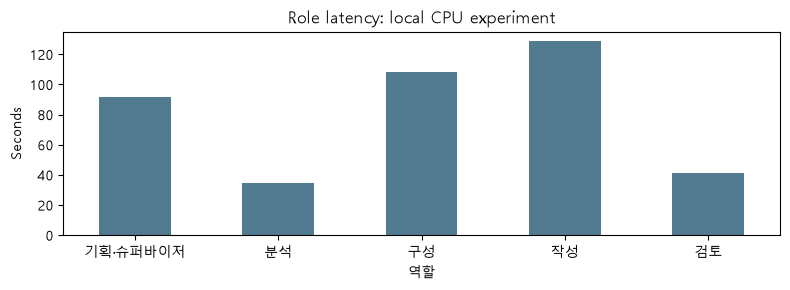

In [3]:
calls = pd.DataFrame([{'역할': names[r['role']], '모델': r['model'], '시간(초)': r['seconds'],
                       '입력 토큰': (r.get('usage') or {}).get('input_tokens'),
                       '출력 토큰': (r.get('usage') or {}).get('output_tokens'),
                       '출력 잘림': r.get('output_truncated', False)} for r in data['calls']])
display(calls)
print('호출 시간 합계:', round(calls['시간(초)'].sum(), 2), '초')
from matplotlib import font_manager
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
cjk_font = next((name for name in ['Malgun Gothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP'] if name in available_fonts), None)
plt.rcParams['font.family'] = cjk_font or 'DejaVu Sans'
plot_calls = calls.copy()
if cjk_font is None:
    plot_calls['역할'] = [record['role'] for record in data['calls']]
plt.rcParams['axes.unicode_minus'] = False
plot_calls.plot.bar(x='역할', y='시간(초)', legend=False, rot=0, figsize=(8, 3), color='#527a91')
plt.title('Role latency: local CPU experiment')
plt.ylabel('Seconds')
plt.tight_layout()
plt.show()

## 4. 검토 결과
별도 검토 사례. 프롬프트가 달라 정식 모델 성능 비교는 아님.

In [4]:
strong_review = json.loads(data['stronger_review']['content'])
reviews = pd.DataFrame([
    {'검사': '1.7B 모델 자체 검토', '승인': data['original_review']['approved']},
    {'검사': '독립 원문 대조', '승인': False},
    {'검사': '4B 별도 검토', '승인': strong_review['approved']}])
display(reviews)
print('확인한 문제:')
for issue in data['audit']['factual_issues']:
    print('-', issue)
print('후속 작성 검사:', data['writer_guard'])

,검사,승인
0,1.7B 모델 자체 검토,True
1,독립 원문 대조,False
2,4B 별도 검토,False


확인한 문제:
- 원본은 학습·성능 평가·배포가 없다고 명시하지만 보고서는 학습 설정과 성능 평가를 수행했다고 서술함.
- 원본에 데이터 전처리·품질 검증 기록이 없으나 수행했다고 서술함.
후속 작성 검사: {'missing_citations': True, 'missing_section_numbers': [], 'note': '구조·근거 ID 검사와 AI 검토 결과입니다. 사실성 전체를 보증하지 않습니다.', 'unknown_source_ids': [], 'unresolved_control_tags': False}
